# 09 · Calibration: when is a pick safe to auto-map?

**The question this step answers:** a mapping method picks a group for an account, with a score. Should we trust that pick and **auto-map** the account, or send it to a person for **review**? D1's rule: auto-map only when, on dev, at least **98%** of the auto-mapped accounts are right. Calibration turns a method's raw score into the chance of being right, and from that chooses the cut-off.

**Where it sits in the pipeline:** after a method has scored its shortlist (notebook 07). Every method (embeddings, XGBoost, Laya, the LLM…) goes through this same step, so their results compare fairly. This notebook shows it on the simplest method, **embeddings top-1**: pick whatever bge-m3 ranks first.

**The code:** `src/d1/mapper/calibrate.py`: `features`, `Calibrator`, `cross_fit_probs`, `choose_threshold`.

In [1]:
import json
from collections import Counter
from random import Random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from d1.config import REPO_ROOT, load_config
from d1.datagen.standard_chart import load_standard_chart
from d1.evaluation.plotting import (
    BLUE_RAMP, COLORS, INK, INK_2, LANGUAGE_COLORS, MUTED, SINGLE, SOURCE_COLORS, SURFACE, apply_style, pct, short,
)

config = load_config()
chart = load_standard_chart(config.data.chart_path, expected=config.data.expected_groups)
by_code = {a.code: a for a in chart}
apply_style()
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.max_rows", 60)

from d1.evaluation.embedding_analysis import load_rows
from d1.mapper.calibrate import Calibrator, choose_threshold, cross_fit_probs, features, precision_curve, reliability_bins

TARGET = config.models.mapping.target_precision
rows = load_rows(REPO_ROOT / "reports" / "embedding_selection_rows.csv")
dev = rows[rows["model"] == config.models.embedding_model].reset_index(drop=True)
dev["right"] = dev["gold_rank"] == 1  # the method's pick (bge-m3's first candidate) is right
X = np.column_stack([dev["top1_score"], dev["top1_score"] - dev["top2_score"]])
y = dev["right"].to_numpy()
COLOR = COLORS[config.models.embedding_model]
print(f"{len(dev)} dev accounts; the first candidate is right for {y.mean():.1%} of them; target precision {TARGET:.0%}")

3500 dev accounts; the first candidate is right for 64.7% of them; target precision 98%


## 1. Two accounts we follow

Two dev accounts, with the scores bge-m3 gave its first and second candidates:

In [2]:
hard = dev[dev["name"] == "En-cours chantier Uccle - Av. Brugmann"].head(1)
# A right pick with a clear lead: among short-named accounts, the one with the biggest lead.
clear = dev[dev["right"] & (dev["name"].str.len() < 35)].assign(lead=lambda d: d["top1_score"] - d["top2_score"]).nlargest(1, "lead")
follow = pd.concat([hard, clear.drop(columns="lead")])
show = pd.DataFrame({
    "account": follow["name"].values,
    "first candidate": [f"{c[0]} {by_code[c[0]].name_en}" for c in follow["top3_codes"]],
    "right group": [f"{c} {by_code[c].name_en}" for c in follow["target_code"]],
    "s1 (top score)": follow["top1_score"].round(3).values,
    "s2 (runner-up)": follow["top2_score"].round(3).values,
})
display(show)

,account,first candidate,right group,s1 (top score),s2 (runner-up)
0,En-cours chantier Uccle - Av. Brugmann,221 Buildings,320 Work in Progress - Acquisition Value,0.485,0.465
1,goodwill,212 Goodwill,212 Goodwill,0.694,0.400


For the first account, bge-m3's first candidate is *Buildings*, which is wrong, and its lead over the runner-up is tiny. For the second, the pick is right and clearly ahead. A good confidence should tell these two apart. The calibrator gets exactly two numbers per account:
- **s1**, the score of the first candidate;
- **s1 − s2**, its lead over the second. A clear winner is more trustworthy than a near tie.

In [3]:
for _, r in follow.iterrows():
    print(f"{r['name'][:45]:45}  features = {np.round(features([r['top1_score'], r['top2_score']]), 3)}")

En-cours chantier Uccle - Av. Brugmann         features = [0.485 0.02 ]
goodwill                                       features = [0.694 0.294]


## 2. The problem: a raw score is not a probability

If the cosine score were a probability, accounts scored 0.7 would be right 70% of the time. They aren't. Grouping the dev accounts by their raw top score and counting how often the pick is right:

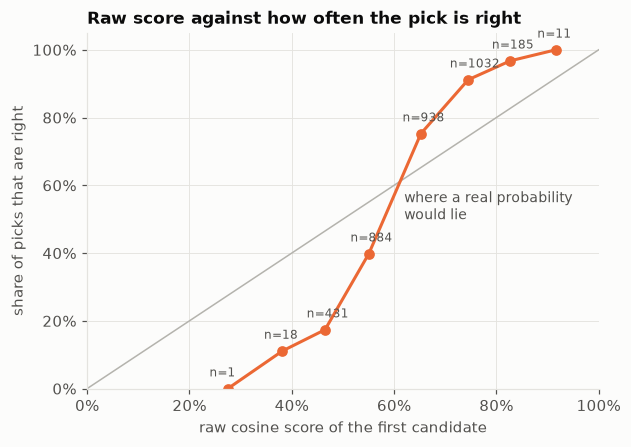

In [4]:
raw = reliability_bins(dev["top1_score"].to_numpy(), y, n_bins=10)
fig, ax = plt.subplots(figsize=(6, 4.2))
ax.plot([0, 1], [0, 1], color=MUTED, linewidth=1)
ax.text(0.62, 0.5, "where a real probability\nwould lie", color=INK_2, fontsize=9)
ax.plot([b["mean_p"] for b in raw], [b["accuracy"] for b in raw], "o-", color=COLOR, markersize=6)
for b in raw:
    ax.annotate(f"n={b['n']}", (b["mean_p"], b["accuracy"]), xytext=(-12, 8), textcoords="offset points", fontsize=8, color=INK_2)
ax.set_xlabel("raw cosine score of the first candidate")
ax.set_ylabel("share of picks that are right")
ax.xaxis.set_major_formatter(pct()); ax.yaxis.set_major_formatter(pct())
ax.set_xlim(0, 1); ax.set_ylim(0, 1.05)
ax.set_title("Raw score against how often the pick is right")
plt.show()

How to read it: every dot is a group of accounts with similar raw scores, and the grey diagonal is where a real probability would lie. The line rises, so a higher score *is* more often right, but the scale is off. Picks scored around 0.75 are right about 90% of the time, and picks around 0.45 only about 17%. The line is much steeper than the diagonal. Each method has its own scale, so raw numbers can't be compared between methods either.

## 3. The two clues together

Every dev account placed by its two numbers. Coloured: the pick is right. Grey: wrong. Right picks sit to the top right: a high score *and* a clear lead.

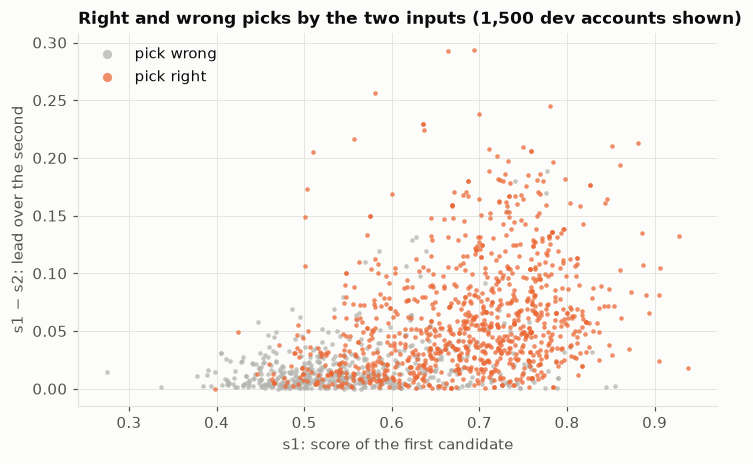

In [5]:
sample = dev.sample(1500, random_state=0)
fig, ax = plt.subplots(figsize=(7.5, 4.4))
for right, color, label, size in [(False, MUTED, "pick wrong", 9), (True, COLOR, "pick right", 9)]:
    part = sample[sample["right"] == right]
    ax.scatter(part["top1_score"], part["top1_score"] - part["top2_score"], s=size, color=color, alpha=0.75, label=label, linewidths=0)
ax.set_xlabel("s1: score of the first candidate")
ax.set_ylabel("s1 − s2: lead over the second")
ax.set_title("Right and wrong picks by the two inputs (1,500 dev accounts shown)")
ax.legend(loc="upper left", markerscale=2)
plt.show()

## 4. Fitting the calibrator, step by step

1. **Fit a logistic regression** on the two inputs: *P(right) = 1 / (1 + e^−(a·s1 + b·lead + c))*. Three numbers to learn, from 3,500 accounts, so it can't overfit.
2. **Do it out of fold.** Split the 70 dev companies into 5 parts. Fit on 4 parts, predict the 5th, and rotate. Every account's probability then comes from a calibrator that **never saw that account**, so the threshold chosen next isn't flattered by fitting and judging on the same rows.
3. **Keep whole companies together** in those parts. Accounts of one company look alike, so splitting a company would leak.
4. **For the saved calibrator,** fit once more on all of dev. That's the one used on new accounts.

The learned weights, from the fit on all of dev:

In [6]:
cal = Calibrator().fit(X, y)
display(pd.Series({"a: weight of s1": cal.coef[0], "b: weight of the lead": cal.coef[1], "c: intercept": cal.intercept}).round(2).to_frame("value"))
p = cross_fit_probs(X, y, folds=5, seed=0, groups=dev["company_id"].to_numpy())
dev["p"] = p
for _, r in dev[dev["account_id"].isin(follow["account_id"])].iterrows():
    print(f"{r['name'][:45]:45}  P(right) = {r['p']:.1%}")

,value
a: weight of s1,10.93
b: weight of the lead,32.22
c: intercept,-7.21


goodwill                                       P(right) = 100.0%
En-cours chantier Uccle - Av. Brugmann         P(right) = 23.0%


Both weights are positive: a higher score and a bigger lead both make a pick more likely right. The lead counts about three times as much per point, because the leads are much smaller numbers. Our two accounts now get probabilities you can act on.

## 5. Are the probabilities honest now?

The same check as in section 2, now with the calibrated, out-of-fold probabilities. If the calibration works, the dots lie on the diagonal: accounts given 80% are right about 80% of the time.

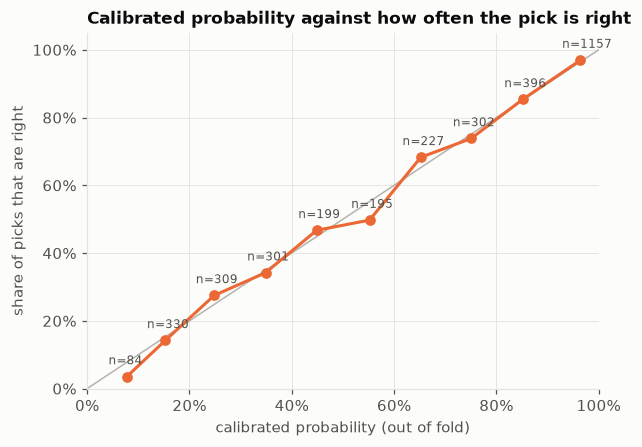

In [7]:
cal_bins = reliability_bins(p, y, n_bins=10)
fig, ax = plt.subplots(figsize=(6, 4.2))
ax.plot([0, 1], [0, 1], color=MUTED, linewidth=1)
ax.plot([b["mean_p"] for b in cal_bins], [b["accuracy"] for b in cal_bins], "o-", color=COLOR, markersize=6)
for b in cal_bins:
    ax.annotate(f"n={b['n']}", (b["mean_p"], b["accuracy"]), xytext=(-12, 8), textcoords="offset points", fontsize=8, color=INK_2)
ax.set_xlabel("calibrated probability (out of fold)")
ax.set_ylabel("share of picks that are right")
ax.xaxis.set_major_formatter(pct()); ax.yaxis.set_major_formatter(pct())
ax.set_xlim(0, 1); ax.set_ylim(0, 1.05)
ax.set_title("Calibrated probability against how often the pick is right")
plt.show()

## 6. Choosing the threshold

Sort the accounts from most to least confident. Auto-mapping the top ones gives a high precision; adding less confident ones gives a bigger **auto-share** (less work for people) but a lower precision. `choose_threshold` takes the **largest auto-share whose precision is still at least 98%**, with at least 50 accounts behind it, so a lucky handful can't set the threshold.

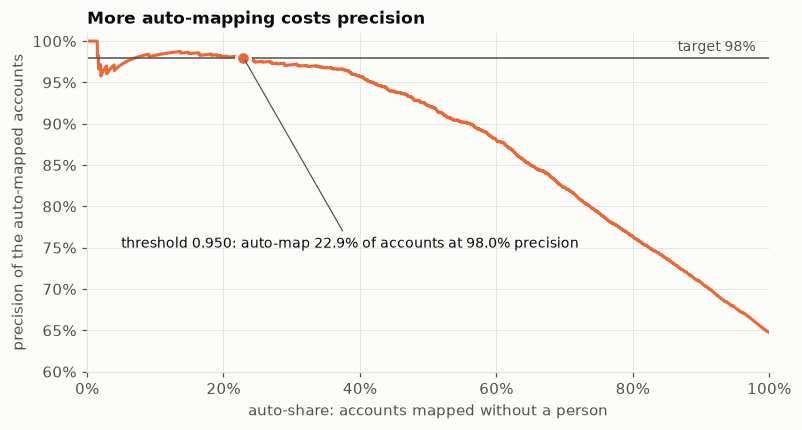

t_auto = 0.9501: 802 of 3500 dev accounts auto-mapped, 786 of them right


In [8]:
curve = precision_curve(p, y)
t_auto = choose_threshold(p, y, TARGET, min_support=50)
at = p >= t_auto
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(curve["auto_share"], curve["precision"], color=COLOR)
ax.axhline(TARGET, color=INK_2, linewidth=1)
ax.text(0.98, TARGET + 0.004, f"target {TARGET:.0%}", ha="right", va="bottom", fontsize=9, color=INK_2)
ax.plot(at.mean(), y[at].mean(), "o", color=COLOR, markersize=9, markeredgecolor=SURFACE, markeredgewidth=2)
ax.annotate(f"threshold {t_auto:.3f}: auto-map {at.mean():.1%} of accounts at {y[at].mean():.1%} precision",
            (at.mean(), y[at].mean()), xytext=(0.05, 0.75), textcoords="data", fontsize=9, color=INK,
            arrowprops={"arrowstyle": "-", "color": INK_2, "linewidth": 0.8})
ax.xaxis.set_major_formatter(pct()); ax.yaxis.set_major_formatter(pct())
ax.set_ylim(0.6, 1.01)
ax.set_xlim(0, 1)
ax.set_xlabel("auto-share: accounts mapped without a person")
ax.set_ylabel("precision of the auto-mapped accounts")
ax.set_title("More auto-mapping costs precision")
plt.show()
print(f"t_auto = {t_auto:.4f}: {at.sum()} of {len(at)} dev accounts auto-mapped, {y[at].sum()} of them right")

## 7. Who gets auto-mapped?

The 98% holds over all of dev, but not for every kind of account:

In [9]:
by = dev.assign(auto=at).groupby("source").apply(lambda g: pd.Series({
    "accounts": len(g), "auto-mapped": g["auto"].mean(),
    "precision when auto-mapped": g.loc[g["auto"], "right"].mean() if g["auto"].any() else np.nan,
}), include_groups=False).reindex(["rules", "llm"])
display(by.style.format({"accounts": "{:.0f}", "auto-mapped": "{:.1%}", "precision when auto-mapped": "{:.1%}"}))

,accounts,auto-mapped,precision when auto-mapped
source,,,
rules,2000,37.3%,99.3%
llm,1500,3.7%,80.4%


**This is the most important table in the notebook.** For the embeddings baseline, almost all auto-mapping happens on rule-based accounts, which are easy. On LLM-written accounts, the realistic ones, it auto-maps very few, and those few are right only about 80% of the time: well below 98%. One overall threshold hides a weak spot, so the evaluation always reports precision per source too. Part of the gap is the LLM's own label errors on dev (about 13% on test, notebook 06), but not all of it.

## 8. Why two inputs and not one

The same threshold search, using only the top score, only the lead, or the calibrated combination:

In [10]:
def result(score):
    t = choose_threshold(score, y, TARGET, min_support=50)
    return {"threshold": t, "auto-share at 98%": (score >= t).mean() if t is not None else 0.0}
display(pd.DataFrame({"s1 only": result(X[:, 0]), "lead only": result(X[:, 1]), "calibrated (both)": result(p)}).T
        .style.format({"threshold": lambda v: "unreachable" if v is None or v != v else f"{v:.3f}", "auto-share at 98%": "{:.1%}"}))

,threshold,auto-share at 98%
s1 only,unreachable,0.0%
lead only,0.192,1.5%
calibrated (both),0.950,22.9%


With the top score alone, 98% precision is never reached with at least 50 accounts: even the highest-scored picks include too many wrong ones. The lead alone does better, and the combination does best. That's why every method is calibrated on both.

## 9. How stable is the threshold?

The out-of-fold split is random. Repeating the whole procedure with 10 different splits:

In [11]:
stab = []
for seed in range(10):
    ps = cross_fit_probs(X, y, folds=5, seed=seed, groups=dev["company_id"].to_numpy())
    t = choose_threshold(ps, y, TARGET, 50)
    stab.append({"seed": seed, "threshold": t, "auto-share": (ps >= t).mean(), "precision": y[ps >= t].mean()})
stab = pd.DataFrame(stab).set_index("seed")
display(stab.style.format({"threshold": "{:.4f}", "auto-share": "{:.1%}", "precision": "{:.1%}"}))
print(f"auto-share between {stab['auto-share'].min():.1%} and {stab['auto-share'].max():.1%}")

,threshold,auto-share,precision
seed,,,
0,0.9501,22.9%,98.0%
1,0.9483,23.2%,98.0%
2,0.9495,23.0%,98.0%
3,0.9524,22.3%,98.1%
4,0.9523,22.2%,98.1%
5,0.9528,22.0%,98.1%
6,0.9539,21.8%,98.0%
7,0.9462,23.5%,98.1%
8,0.9473,23.5%,98.1%


auto-share between 21.8% and 23.5%


## 10. What is *not* happening

- **Nothing about the embedding model changes.** Calibration doesn't fine-tune bge-m3. It's a separate three-number model on top of the scores.
- **These are not the final thresholds.** This notebook calibrates one method to show the step. Task 2.4 calibrates every method the same way and saves its calibrator and threshold under `artifacts/methods/<name>/`.
- **Test is not used.** The threshold is chosen on dev only. The test pile later shows whether 98% still holds on accounts the threshold never saw.